# Лабораторная работа 1
`Буданов Максим гр.6231`   
`Вариант 1`

1) Классификация данных методом k ближайших соседей ( kNN)

2) Классификация данных методом опорных векторов (SVM)

3) Построение softmax-классификатора

Вариант 1: задания 1 и 2 на наборе данных CIFAR-10

## 1. Классификация данных методом k ближайших соседей ( kNN)

In [5]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scripts.data_utils import load_CIFAR10

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) 
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

1.1 Скачайте данные в соответсвии с заданием.

CIFAR-10 по ссылке https://www.cs.toronto.edu/~kriz/cifar.html
или используйте  команду !bash get_datasets.sh (google colab, local ubuntu)

MNIST 
sklearn.datasets import load_digits
digits = load_digits()

In [6]:
cifar10_dir = 'scripts/datasets/cifar-10-batches-py'

try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Clear previously loaded data.
Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


1.2 Выведите несколько примеров изображений из обучающей выборки для каждого класса.



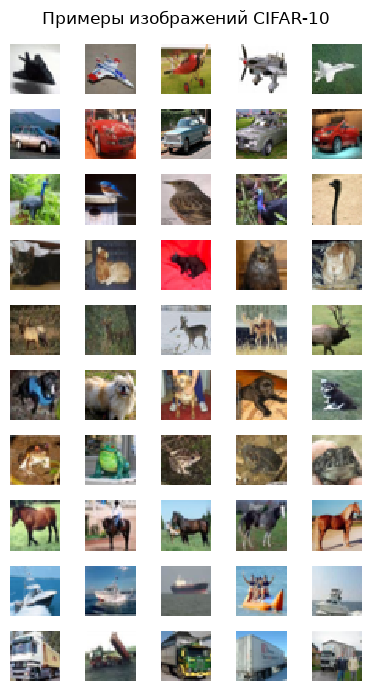

In [7]:
class_names = ['plane', 'car', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

fig, axes = plt.subplots(10, 5, figsize=(4, 7))
for class_id in range(10):
    images_ids = np.where(y_train == class_id)[0][:5]
    for j, image_id in enumerate(images_ids):
        axes[class_id, j].imshow(X_train[image_id].astype('uint8'))
        axes[class_id, j].axis('off')
        if j == 0:
            axes[class_id, j].set_ylabel(class_names[class_id], rotation=0,
                                         labelpad=45, va='center')
plt.suptitle('Примеры изображений CIFAR-10')
plt.tight_layout()
plt.show()

1.3 Разделите данные на обучающу и тестовую выборки (X_train, y_train, X_test, y_test). Преобразуйте каждое изображение в одномерный массив. 

In [9]:
X_train = X_train.reshape(len(X_train), -1).astype(np.float32)
y_train = y_train.copy()
X_test = X_test.reshape(len(X_test), -1).astype(np.float32)
y_test = y_test.copy()

print('Размер X_train после преобразования:', X_train.shape)
print('Размер X_test после преобразования:', X_test.shape)

Размер X_train после преобразования: (50000, 3072)
Размер X_test после преобразования: (10000, 3072)


1.4 Напишите реализацию классификатора в скрипте /classifiers/k_nearest_neighbor.py и обучите его на сформированной выборке. 

In [10]:
import importlib
import scripts
from scripts.classifiers import KNearestNeighbor

importlib.reload(scripts)

classifier = KNearestNeighbor()
classifier.train(X_train, y_train)

1.5 Выполните классификацию на тестовой выборке

In [11]:
y_test_pred = classifier.predict(X_test, k=3)
print('Первые 20 предсказанных меток:', y_test_pred[:20])
print('Первые 20 правильных меток:   ', y_test[:20])

Первые 20 предсказанных меток: [2. 8. 8. 0. 4. 6. 2. 2. 4. 8. 0. 8. 5. 2. 4. 0. 5. 2. 1. 3.]
Первые 20 правильных меток:    [3 8 8 0 6 6 1 6 3 1 0 9 5 7 9 8 5 7 8 6]


1.6 Визуализируйте матрицу расстояний для каждого изображения из тестовой выборки до изображений из обучающей выборки. 


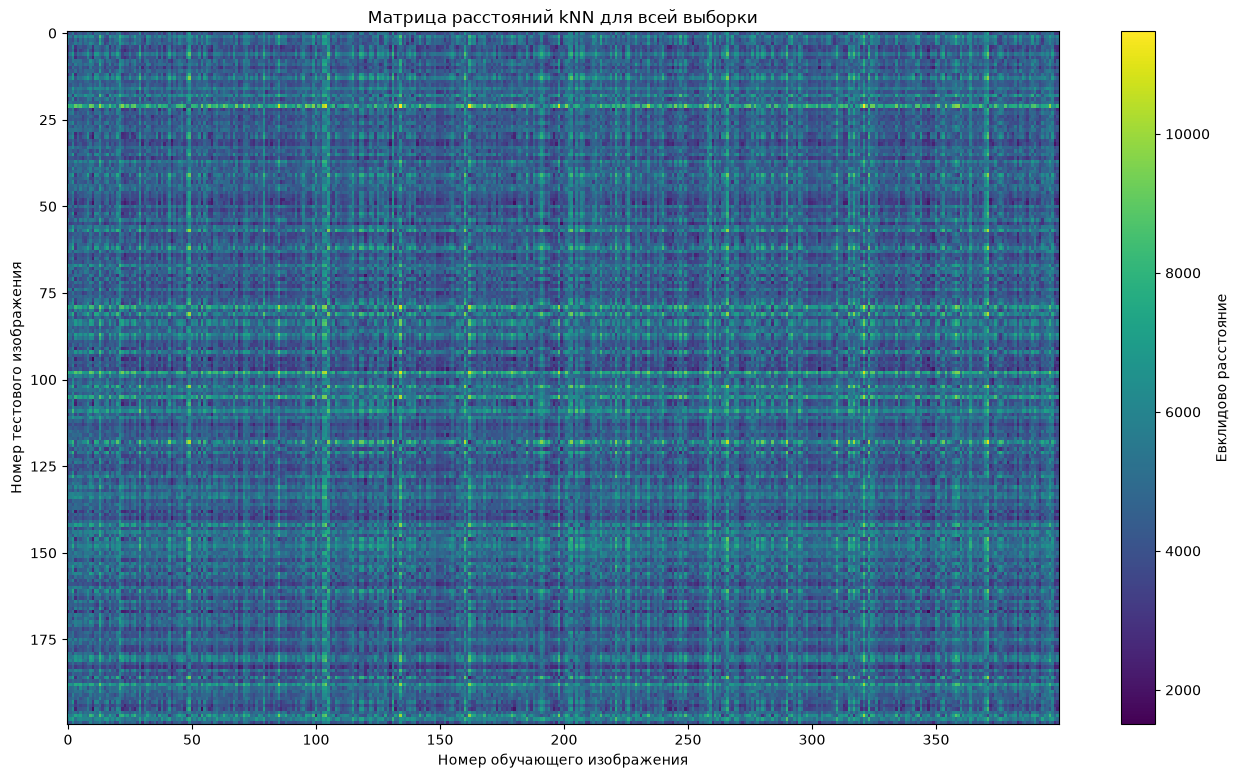

Размер полной матрицы расстояний: (10000, 50000)


In [12]:
dists = classifier.compute_distances_no_loops(X_test)

plt.figure(figsize=(16, 9))
plt.imshow(dists[:200, :400], aspect='auto', cmap='viridis')
plt.colorbar(label='Евклидово расстояние')
plt.xlabel('Номер обучающего изображения')
plt.ylabel('Номер тестового изображения')
plt.title('Матрица расстояний kNN для всей выборки')
plt.show()
print('Размер полной матрицы расстояний:', dists.shape)


1.7 Посчитайте долю правильно классифицированных изображений из тестовой выборки.


In [13]:
knn_accuracy = np.mean(y_test_pred == y_test)
print('Точность kNN при k=3: {:.4f}'.format(knn_accuracy))

Точность kNN при k=3: 0.3302


1.8 Постройте график зависимости доли правильно классифицированных изображений от числа соседей, используемых при классификации.

k =  1, accuracy = 0.3539
k =  3, accuracy = 0.3302
k =  5, accuracy = 0.3398
k =  7, accuracy = 0.3357
k = 10, accuracy = 0.3385


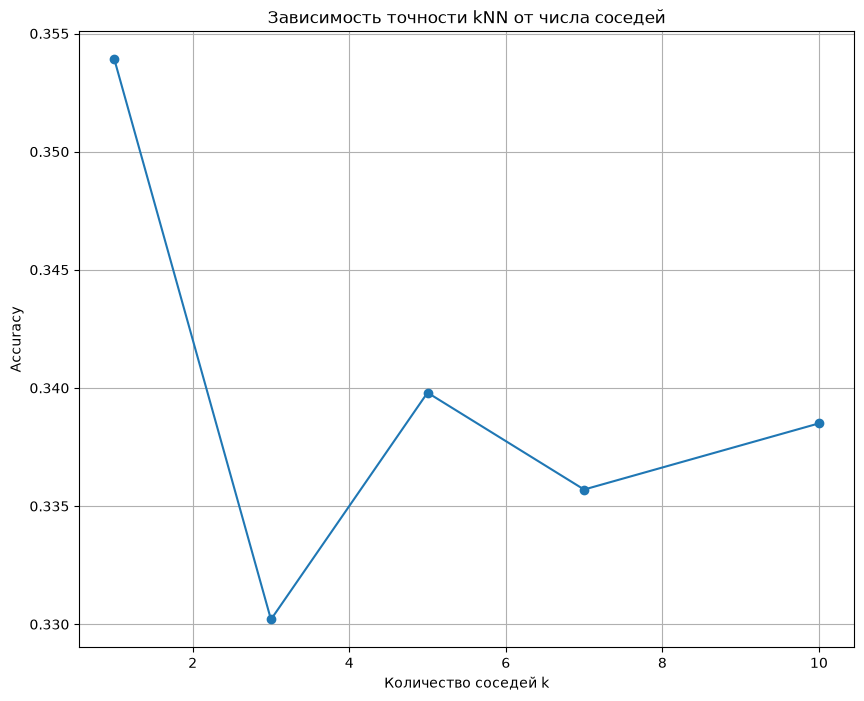

In [14]:
k_values = [1, 3, 5, 7, 10]
knn_accuracies = []

for k in k_values:
    pred = classifier.predict(X_test, k=k)
    acc = np.mean(pred == y_test)
    knn_accuracies.append(acc)
    print(f'k = {k:2d}, accuracy = {acc:.4f}')

plt.plot(k_values, knn_accuracies, marker='o')
plt.xlabel('Количество соседей k')
plt.ylabel('Accuracy')
plt.title('Зависимость точности kNN от числа соседей')
plt.grid(True)
plt.show()

1.9 Выберите лучшее значение параметра k на основе кросс-валидации.


In [15]:
folds = np.array_split(np.random.permutation(len(X_train)), 3)
k_choices = [1, 3, 5, 7, 10]
k_to_accuracies = {k: [] for k in k_choices}

for k in k_choices:
    for fold_id in range(3):
        val_ids = folds[fold_id]
        train_ids_cv = np.concatenate([folds[j] for j in range(3) if j != fold_id])

        cv_classifier = KNearestNeighbor()
        cv_classifier.train(X_train[train_ids_cv], y_train[train_ids_cv])
        val_pred = cv_classifier.predict(X_train[val_ids], k=k)
        fold_accuracy = np.mean(val_pred == y_train[val_ids])
        k_to_accuracies[k].append(fold_accuracy)

for k in k_choices:
    print(f'k = {k}: accuracies = {np.round(k_to_accuracies[k], 4)}, среднее = {np.mean(k_to_accuracies[k]):.4f}')
best_k = max(k_choices, key=lambda k: np.mean(k_to_accuracies[k]))
print('Лучшее значение k по кросс-валидации:', best_k)

k = 1: accuracies = [0.3337 0.3341 0.3339], среднее = 0.3339
k = 3: accuracies = [0.3152 0.3153 0.3207], среднее = 0.3170
k = 5: accuracies = [0.3247 0.3209 0.3288], среднее = 0.3248
k = 7: accuracies = [0.3257 0.3255 0.3286], среднее = 0.3266
k = 10: accuracies = [0.326  0.3231 0.3295], среднее = 0.3262
Лучшее значение k по кросс-валидации: 1



1.10 Переобучите и протестируйте классификатор с использованием выбранного значения k.



In [16]:
best_knn = KNearestNeighbor()
best_knn.train(X_train, y_train)
best_knn_pred = best_knn.predict(X_test, k=best_k)
best_knn_accuracy = np.mean(best_knn_pred == y_test)
print(f'Итоговая accuracy kNN при k={best_k}: {best_knn_accuracy:.4f}')

Итоговая accuracy kNN при k=1: 0.3539


1.11 Сделайте выводы по результатам 1 части задания.

В этой части был реализован и проверен классификатор kNN. Для выбора параметра k использовалась кросс-валидация, после чего модель была повторно обучена на всей обучающей выборке и проверена на тестовой.

По полученным значениям accuracy можно сравнить качество при разных k. Метод kNN использует расстояния между изображениями, поэтому для CIFAR-10 он может работать не очень точно: изображения одного класса могут заметно отличаться, а разные классы иногда имеют похожие цвета и формы. Кроме того, при большом количестве изображений вычисление расстояний занимает много времени.

Был осущестлвен подбор лучшего k для kNN. На мое удивление, что по результатам на тестовой выборке, что по результатам кросс-валидации наилучшее k=1

## 2.  Классификация данных методом опорных векторов (SVM)

2.1 Разделите исходную обучающую выборку на обучающую и валидационную части, тестовую выборку оставьте отдельно. Все изображения должны быть использованы. Преобразуйте каждое изображение в одномерный массив. Выведите размеры выборок.

In [17]:
cifar10_dir = 'scripts/datasets/cifar-10-batches-py'

try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Clear previously loaded data.
Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


In [18]:
from scripts.classifiers.linear_svm import svm_loss_vectorized
import time

X_all = X_train.reshape(len(X_train), -1).astype(np.float32)
y_all = y_train.copy()
X_test = X_test.reshape(len(X_test), -1).astype(np.float32)
y_test = y_test.copy()

X_train = X_all[:40000].copy()
y_train = y_all[:40000].copy()
X_val = X_all[40000:].copy()
y_val = y_all[40000:].copy()

X_dev = X_train.copy()
y_dev = y_train.copy()

print('Размер обучающей выборки:', X_train.shape, y_train.shape)
print('Размер валидационной выборки:', X_val.shape, y_val.shape)
print('Размер тестовой выборки:', X_test.shape, y_test.shape)
print('Размер выборки для проверки функций:', X_dev.shape, y_dev.shape)

Размер обучающей выборки: (40000, 3072) (40000,)
Размер валидационной выборки: (10000, 3072) (10000,)
Размер тестовой выборки: (10000, 3072) (10000,)
Размер выборки для проверки функций: (40000, 3072) (40000,)


2.2 Проведите предварительную обработку данных, путем вычитания среднего изображения, рассчитанного  по обучающей выборке.

2.3 Чтобы далее не учитывать смещение (свободный член b), добавьте дополнитульную размерность к массиву дынных и заполните ее 1.

[130.89912 136.1391  132.54753 130.2976  135.49132 131.80087 131.2357
 136.31682 132.54535 131.7664 ]


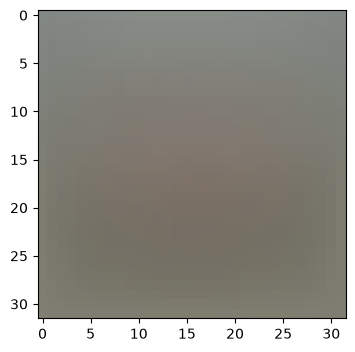

(40000, 3073) (10000, 3073) (10000, 3073)


In [19]:
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10]) 
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8')) 
plt.show()

X_train -= mean_image
X_val -= mean_image
X_test -= mean_image

X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])


print(X_train.shape, X_val.shape, X_test.shape)

In [20]:
X_dev -= mean_image
X_dev = np.hstack([X_dev, np.ones((X_dev.shape[0], 1))])
print('Размер X_dev после обработки:', X_dev.shape)

Размер X_dev после обработки: (40000, 3073)


2.4 Реализуйте loss-функции в scripts/classifiers/linear_svm.py



In [21]:
from scripts.classifiers.linear_svm import svm_loss_naive

W = np.random.randn(3073, 10) * 0.0001

loss, grad = svm_loss_naive(W, X_dev, y_dev, 0.000005)
print('loss: %f' % loss)

loss: 9.056345



2.5 Убедитесь, что вы верно реализовали расчет градиента, сравнив с реализацией численными методами (код приведен ниже).

In [22]:
loss, grad = svm_loss_naive(W, X_dev, y_dev, 0.0)

from scripts.gradient_check import grad_check_sparse
f = lambda w: svm_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad)

loss, grad = svm_loss_naive(W, X_dev, y_dev, 5e1)
f = lambda w: svm_loss_naive(w, X_dev, y_dev, 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad)

numerical: 27.640457 analytic: 27.641922, relative error: 2.649734e-05
numerical: -3.008532 analytic: -3.011806, relative error: 5.437889e-04
numerical: 6.291882 analytic: 6.290818, relative error: 8.461682e-05
numerical: -8.757003 analytic: -8.755814, relative error: 6.790571e-05
numerical: -3.740506 analytic: -3.738368, relative error: 2.859772e-04
numerical: 13.284159 analytic: 13.282321, relative error: 6.919151e-05
numerical: 21.769485 analytic: 21.770280, relative error: 1.824579e-05
numerical: 9.203738 analytic: 9.204259, relative error: 2.826093e-05
numerical: -12.662979 analytic: -12.665889, relative error: 1.148792e-04
numerical: 20.429413 analytic: 20.432469, relative error: 7.477354e-05
numerical: 10.387013 analytic: 10.388622, relative error: 7.746862e-05
numerical: -9.857407 analytic: -9.855306, relative error: 1.065346e-04
numerical: 0.992190 analytic: 0.991254, relative error: 4.721356e-04
numerical: 1.085597 analytic: 1.086886, relative error: 5.931585e-04
numerical: 1

2.6 Сравните svm_loss_naive и svm_loss_vectorized реализации

In [23]:
tic = time.time()
_, grad_naive = svm_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Naive loss and gradient: computed in %fs' % (toc - tic))

tic = time.time()
_, grad_vectorized = svm_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Vectorized loss and gradient: computed in %fs' % (toc - tic))

difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('difference: %f' % difference)

Naive loss and gradient: computed in 2.363999s
Vectorized loss and gradient: computed in 0.071141s
difference: 0.000000


2.7 Реализуйте стохастический градиентный спуск в /classifiers/linear_classifier.py . Реализуйте методы train() и predict() и запустите следующий код

In [24]:
from scripts.classifiers import LinearSVM
svm = LinearSVM()
tic = time.time()
loss_hist = svm.train(X_train, y_train, learning_rate=1e-7, reg=2.5e4,
                      num_iters=1500, verbose=True)
toc = time.time()
print('That took %fs' % (toc - tic))

iteration 0 / 1500: loss 789.337949
iteration 100 / 1500: loss 288.953856
iteration 200 / 1500: loss 108.063008
iteration 300 / 1500: loss 42.871844
iteration 400 / 1500: loss 19.166710
iteration 500 / 1500: loss 10.802449
iteration 600 / 1500: loss 7.262949
iteration 700 / 1500: loss 6.343886
iteration 800 / 1500: loss 5.367900
iteration 900 / 1500: loss 5.394000
iteration 1000 / 1500: loss 5.198374
iteration 1100 / 1500: loss 4.883637
iteration 1200 / 1500: loss 5.396048
iteration 1300 / 1500: loss 5.579368
iteration 1400 / 1500: loss 5.486948
That took 1.313588s


In [25]:
y_train_pred = svm.predict(X_train)
print('training accuracy: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = svm.predict(X_val)
print('validation accuracy: %f' % (np.mean(y_val == y_val_pred), ))

training accuracy: 0.371900
validation accuracy: 0.361300


2.8 С помощью кросс-валидации выберите значения параметров скорости обучения и регуляризации. В кросс-валидации используйте обучающую и валидационную выборки. Оцените accuracy на тестовой выборке.

In [28]:
learning_rates = [1e-7, 5e-7, 2e-8]
regularization_strengths = [15000, 20000, 25000, 50000]

In [29]:
svm_results = {}
best_val_accuracy = -1
best_learning_rate = None
best_reg = None

for learning_rate in learning_rates:
    for reg in regularization_strengths:
        model = LinearSVM()
        model.train(X_train, y_train,
                    learning_rate=learning_rate,
                    reg=reg,
                    num_iters=800,
                    verbose=False)
        val_pred = model.predict(X_val)
        val_accuracy = np.mean(val_pred == y_val)
        svm_results[(learning_rate, reg)] = val_accuracy
        print('learning_rate = {}, reg = {}, val accuracy = {:.4f}'.format(
            learning_rate, reg, val_accuracy))

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_learning_rate = learning_rate
            best_reg = reg

print('Лучшие параметры:', best_learning_rate, best_reg)
print('Лучшая validation accuracy:', best_val_accuracy)

learning_rate = 1e-07, reg = 15000, val accuracy = 0.3603
learning_rate = 1e-07, reg = 20000, val accuracy = 0.3649
learning_rate = 1e-07, reg = 25000, val accuracy = 0.3654
learning_rate = 1e-07, reg = 50000, val accuracy = 0.3511
learning_rate = 5e-07, reg = 15000, val accuracy = 0.3354
learning_rate = 5e-07, reg = 20000, val accuracy = 0.3296
learning_rate = 5e-07, reg = 25000, val accuracy = 0.3217
learning_rate = 5e-07, reg = 50000, val accuracy = 0.3066
learning_rate = 2e-08, reg = 15000, val accuracy = 0.2514
learning_rate = 2e-08, reg = 20000, val accuracy = 0.2486
learning_rate = 2e-08, reg = 25000, val accuracy = 0.2621
learning_rate = 2e-08, reg = 50000, val accuracy = 0.3047
Лучшие параметры: 1e-07 25000
Лучшая validation accuracy: 0.3654


In [30]:
X_train_final = np.concatenate([X_train, X_val], axis=0)
y_train_final = np.concatenate([y_train, y_val], axis=0)

best_svm = LinearSVM()
best_svm.train(X_train_final, y_train_final,
               learning_rate=best_learning_rate,
               reg=best_reg,
               num_iters=1500,
               verbose=True)

y_test_pred_svm = best_svm.predict(X_test)
svm_test_accuracy = np.mean(y_test_pred_svm == y_test)
print('Итоговая accuracy SVM на тестовой выборке: {:.4f}'.format(
    svm_test_accuracy))

iteration 0 / 1500: loss 783.969571
iteration 100 / 1500: loss 285.398912
iteration 200 / 1500: loss 106.818231
iteration 300 / 1500: loss 42.654611
iteration 400 / 1500: loss 18.602574
iteration 500 / 1500: loss 10.244022
iteration 600 / 1500: loss 6.943837
iteration 700 / 1500: loss 5.504745
iteration 800 / 1500: loss 5.259681
iteration 900 / 1500: loss 5.312064
iteration 1000 / 1500: loss 5.200332
iteration 1100 / 1500: loss 5.476591
iteration 1200 / 1500: loss 5.408960
iteration 1300 / 1500: loss 5.471319
iteration 1400 / 1500: loss 5.534107
Итоговая accuracy SVM на тестовой выборке: 0.3639


2.9 Сделайте выводы по второй части задания. Укажите полученную точность на тестовой выборке и выбранные значения learning_rate и reg.

Во втором задании был реализован метод SVM для классификации изображений CIFAR-10.   
В ходе работы был выполнен подбор гиперпараметров по валидационной выборке.   
Лучшая модель показала accuracy на валидационной выборке — 0.3654, на тестовой выборке — 0.3639.   
Полученные результаты показывают, что SVM в целом подходит для построения базовой модели классификации,   
но качество ограничено сложностью изображений и использованием исходных признаков.